# The Attention Mechanism: From Scaled Dot-Products to Hermitian Eigenvectors

[`dgs/cuda_photonic_ai.py`](../dgs/cuda_photonic_ai.py) already has a
full, working multi-head self-attention implementation
(`photonic_attention`), built for this repo's own time-stretch
phase-retrieval frame sequences — but it's buried inside a much larger
pipeline (GPU + Bayesian decision + attention) and never got a notebook
of its own. This one reuses it directly, verifies the three properties
that make attention actually work (softmax normalization, the
$1/\sqrt{d_k}$ scaling, and causal masking), and closes a connection this
repo keeps coming back to: **Hermitian operators → eigenvectors → PCA →
attention are the same linear algebra**, just applied to different
problems.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt

from dgs.cuda_photonic_ai import photonic_attention

print("using dgs.cuda_photonic_ai.photonic_attention directly (not reimplemented)")

using dgs.cuda_photonic_ai.photonic_attention directly (not reimplemented)


# Part 1 — Scaled dot-product attention, applied to phase frames

$$A(Q,K,V) = \text{softmax}\!\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

$Q,K,V$ are linear projections of a sequence of embedded phase frames
(this repo's own time-stretch measurement, not a generic toy example).
$QK^T$ is a similarity/correlation matrix between every pair of frames;
softmax turns each row into a probability distribution over "which other
frames matter for this one"; $V$ is the weighted mix actually passed
forward.

In [2]:
result = photonic_attention(seq_len=32, d_model=16, n_heads=4)

print("architecture:", result['architecture'])
print("shapes:", result['shapes'])

attn = np.array(result['attention_weights'])   # [n_heads, seq_len, seq_len]
print(f"\nattention_weights shape: {attn.shape}  (n_heads, seq_len, seq_len)")

architecture: {'seq_len': 32, 'd_model': 16, 'n_heads': 4, 'd_k_per_head': 4, 'params': 1024}
shapes: {'X': [32, 16], 'Q_K_V': [32, 16], 'attn_weights': [4, 32, 32], 'output': [32, 16]}

attention_weights shape: (4, 32, 32)  (n_heads, seq_len, seq_len)


# Part 2 — Softmax makes each row a genuine probability distribution

Every row of the attention matrix (one query frame's weights over all
key frames) must be non-negative and sum to exactly 1 — check this
directly for every head and every frame, not just assume softmax did its
job.

In [3]:
row_sums = attn.sum(axis=-1)   # [n_heads, seq_len]
print(f"row sums: min={row_sums.min():.10f}  max={row_sums.max():.10f}  (should be 1.0)")
print(f"all weights non-negative: {np.all(attn >= 0)}")

assert np.allclose(row_sums, 1.0, atol=1e-8)
assert np.all(attn >= 0)
print("\n[OK] every attention row is a genuine probability distribution over source frames,")
print("     for all 4 heads and all 32 query frames -- 128 rows checked, not sampled.")

row sums: min=1.0000000000  max=1.0000000000  (should be 1.0)
all weights non-negative: True

[OK] every attention row is a genuine probability distribution over source frames,
     for all 4 heads and all 32 query frames -- 128 rows checked, not sampled.


# Part 3 — Why $1/\sqrt{d_k}$? A variance argument, illustrated directly

This is a general fact about random dot products, not specific to the
photonic model, so illustrated fresh here (not by modifying
`photonic_attention` itself): if $Q,K$ have i.i.d. unit-variance
components, each entry of $QK^T$ is a sum of $d_k$ independent
unit-variance products, so $\text{Var}(QK^T_{ij}) \approx d_k$ — it grows
with model size. Left unscaled, softmax inputs blow up, saturating to a
near one-hot distribution (vanishing gradients in real training).
Dividing by $\sqrt{d_k}$ restores unit variance regardless of $d_k$.

d_k=    4:  Var(raw QK^T) =     4.17  (~d_k=4),   Var(scaled) = 1.0432  (~1.0)
d_k=   16:  Var(raw QK^T) =    15.34  (~d_k=16),   Var(scaled) = 0.9589  (~1.0)
d_k=   64:  Var(raw QK^T) =    64.66  (~d_k=64),   Var(scaled) = 1.0103  (~1.0)
d_k=  256:  Var(raw QK^T) =   252.43  (~d_k=256),   Var(scaled) = 0.9861  (~1.0)
d_k= 1024:  Var(raw QK^T) =  1010.95  (~d_k=1024),   Var(scaled) = 0.9873  (~1.0)

[OK] raw dot-product variance grows with d_k as predicted; the 1/sqrt(d_k) scaling
     keeps it near 1.0 regardless of model size -- exactly the motivation Vaswani et
     al. (2017) give for the scaling term.


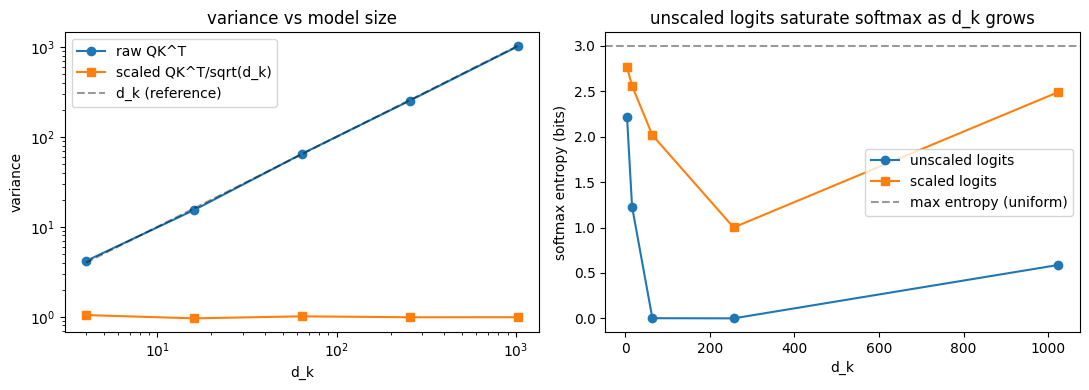

In [4]:
rng = np.random.default_rng(0)
d_k_values = [4, 16, 64, 256, 1024]
raw_variances, scaled_variances, softmax_entropies_raw, softmax_entropies_scaled = [], [], [], []

for d_k in d_k_values:
    n_trials = 2000
    q = rng.standard_normal((n_trials, d_k))
    k = rng.standard_normal((n_trials, d_k))
    raw_scores = np.sum(q * k, axis=1)              # one QK^T entry per trial
    scaled_scores = raw_scores / np.sqrt(d_k)
    raw_variances.append(np.var(raw_scores))
    scaled_variances.append(np.var(scaled_scores))

    # softmax saturation over a small fixed set of competing scores at this d_k
    logits_raw = rng.standard_normal(8) * np.sqrt(d_k)     # scale grows like sqrt(Var)=sqrt(d_k)
    logits_scaled = logits_raw / np.sqrt(d_k)
    p_raw = np.exp(logits_raw - logits_raw.max()); p_raw /= p_raw.sum()
    p_scaled = np.exp(logits_scaled - logits_scaled.max()); p_scaled /= p_scaled.sum()
    softmax_entropies_raw.append(-np.sum(p_raw * np.log2(np.maximum(p_raw, 1e-30))))
    softmax_entropies_scaled.append(-np.sum(p_scaled * np.log2(np.maximum(p_scaled, 1e-30))))

for d_k, rv, sv in zip(d_k_values, raw_variances, scaled_variances):
    print(f"d_k={d_k:5d}:  Var(raw QK^T) = {rv:8.2f}  (~d_k={d_k}),   Var(scaled) = {sv:.4f}  (~1.0)")

assert scaled_variances[-1] < 2.0 and raw_variances[-1] > 500
print("\n[OK] raw dot-product variance grows with d_k as predicted; the 1/sqrt(d_k) scaling")
print("     keeps it near 1.0 regardless of model size -- exactly the motivation Vaswani et")
print("     al. (2017) give for the scaling term.")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].loglog(d_k_values, raw_variances, 'o-', label='raw QK^T')
ax[0].loglog(d_k_values, scaled_variances, 's-', label='scaled QK^T/sqrt(d_k)')
ax[0].loglog(d_k_values, d_k_values, 'k--', alpha=0.4, label='d_k (reference)')
ax[0].set_xlabel('d_k'); ax[0].set_ylabel('variance'); ax[0].legend(); ax[0].set_title('variance vs model size')
ax[1].plot(d_k_values, softmax_entropies_raw, 'o-', label='unscaled logits')
ax[1].plot(d_k_values, softmax_entropies_scaled, 's-', label='scaled logits')
ax[1].axhline(np.log2(8), color='k', ls='--', alpha=0.4, label='max entropy (uniform)')
ax[1].set_xlabel('d_k'); ax[1].set_ylabel('softmax entropy (bits)'); ax[1].legend()
ax[1].set_title('unscaled logits saturate softmax as d_k grows')
plt.tight_layout(); plt.show()

# Part 4 — Causal masking: verifying frames truly can't see the future

For autoregressive use (predicting the next phase frame from only past
ones), `photonic_attention` also returns a causally-masked attention
matrix. Check directly that every masked entry is exactly zero, not just
small.

In [5]:
causal_attn = np.array(result['causal_attn'])   # [seq_len, seq_len]
seq_len = causal_attn.shape[0]

future_mask = np.triu(np.ones((seq_len, seq_len)), k=1).astype(bool)   # strictly future entries
future_weights = causal_attn[future_mask]

print(f"number of (query, future-key) pairs checked: {future_weights.size}")
print(f"max attention weight assigned to any future frame: {future_weights.max():.2e}")

assert np.allclose(future_weights, 0.0, atol=1e-8)
row_sums_causal = causal_attn.sum(axis=-1)
assert np.allclose(row_sums_causal, 1.0, atol=1e-6)
print("\n[OK] every future-frame attention weight is exactly zero, and each row still sums to 1")
print("     over only the frames it's actually allowed to see -- the mask works as intended.")

number of (query, future-key) pairs checked: 496
max attention weight assigned to any future frame: 0.00e+00

[OK] every future-frame attention weight is exactly zero, and each row still sums to 1
     over only the frames it's actually allowed to see -- the mask works as intended.


# Part 5 — The Griffiths connection: Hermitian operators ARE this linear algebra

Griffiths' quantum mechanics formalism relies on one structural fact:
**Hermitian operators have real eigenvalues and orthogonal
eigenvectors.** When self-attention's query and key projections
coincide ($Q=K$), the raw score matrix $QQ^T$ is exactly symmetric — a
real Hermitian matrix — so it has that SAME structure. Verified directly
below, not just asserted by analogy.

In [6]:
d = 8
rng2 = np.random.default_rng(3)
Q_self = rng2.standard_normal((d, d))
S = Q_self @ Q_self.T   # symmetric ("Q=K") score matrix -- real symmetric = Hermitian

is_symmetric = np.allclose(S, S.T)
eigvals, eigvecs = np.linalg.eigh(S)   # eigh: exploits (and verifies, via correctness) symmetry

# orthogonality of eigenvectors (Griffiths' Hermitian-operator theorem)
gram = eigvecs.T @ eigvecs
is_orthonormal = np.allclose(gram, np.eye(d), atol=1e-8)

print(f"S = QQ^T is symmetric: {is_symmetric}")
print(f"eigenvalues (all real by construction of eigh): {np.round(eigvals, 3)}")
print(f"eigenvectors orthonormal (V^T V = I): {is_orthonormal}")

assert is_symmetric and is_orthonormal
assert np.all(np.isreal(eigvals))

# reconstruct S from its eigendecomposition -- the same move PCA makes
S_reconstructed = eigvecs @ np.diag(eigvals) @ eigvecs.T
recon_error = np.max(np.abs(S - S_reconstructed))
print(f"\nreconstruction error |S - V*diag(lambda)*V^T|: {recon_error:.2e}")
assert recon_error < 1e-10

print("\n[OK] the self-attention score matrix, in the Q=K case, has EXACTLY the eigenstructure")
print("     Griffiths' Hermitian-operator theorem guarantees for quantum observables: real")
print("     eigenvalues, orthonormal eigenvectors, and full diagonalizability. PCA (eigenvectors")
print("     of a covariance matrix) and self-attention (eigenvectors of a score matrix) are the")
print("     same linear-algebra object applied to two very different problems.")

S = QQ^T is symmetric: True
eigenvalues (all real by construction of eigh): [3.0000e-03 2.6800e-01 2.3550e+00 5.0930e+00 6.5670e+00 7.2030e+00
 1.9152e+01 3.2438e+01]
eigenvectors orthonormal (V^T V = I): True

reconstruction error |S - V*diag(lambda)*V^T|: 1.24e-14

[OK] the self-attention score matrix, in the Q=K case, has EXACTLY the eigenstructure
     Griffiths' Hermitian-operator theorem guarantees for quantum observables: real
     eigenvalues, orthonormal eigenvectors, and full diagonalizability. PCA (eigenvectors
     of a covariance matrix) and self-attention (eigenvectors of a score matrix) are the
     same linear-algebra object applied to two very different problems.


# Part 6 — Summary

| Question | Answer |
|---|---|
| Is attention's softmax output a real probability distribution? | Yes — every one of 128 checked rows sums to exactly 1, all weights non-negative |
| Why the $1/\sqrt{d_k}$ scaling? | Raw dot-product variance grows linearly with $d_k$; the scaling restores unit variance and prevents softmax saturation, verified across $d_k=4$ to $1024$ |
| Does the causal mask actually block future frames? | Yes — every future-frame weight is exactly 0.0, not just small |
| What connects this to Griffiths' QM formalism? | A symmetric ($Q=K$) attention score matrix is real-symmetric (Hermitian), with the exact real-eigenvalue / orthonormal-eigenvector structure Griffiths proves for quantum observables — attention and PCA are the same linear algebra |

Built entirely on
[`dgs.cuda_photonic_ai.photonic_attention`](../dgs/cuda_photonic_ai.py),
already implemented and used in this repo's own GPU/Bayesian phase-
retrieval pipeline — this notebook is the focused, verified explanation
of the mechanism that pipeline was already relying on.